# **Covid 19 Forecasting - Prophet Model**

# Issues with the Traditional Models - ARIMA/SARIMA

1) **They assume the Time series is Stationary**

ARIMA/SARIMA models require the data to be stationary.

2) **Statistial Knowledge is Required**

3) **We have to handle the Null Values and Outliers before using the Models**

4) **Hard to define the p,d,q values**

5) **Hard to handle multiple seasonalities**

6) **Hard to incoperate real world events/ holidays that affect the time series**

7) **Scalability issue and hard to use in real world dataset and businesses**

8) **Hard to Interpret**

# Prophet Model

- Prophet is a Time series forecasting model built by the Data Science team at Facebook in 2017.
- It was designed because the traditional models have a lot of issues when used in real world datasets and scenarios( They are slow, hard to use, hard to interpret, non-scalable....)
- Porphet is a easy to use model, which requires little knowlegde of stats or forecasting.
- It is a scalable model which can be used to real world datasets.
- It is a Line fitting / Curve Fitting model : It finds the equation of the line which best fits the time series.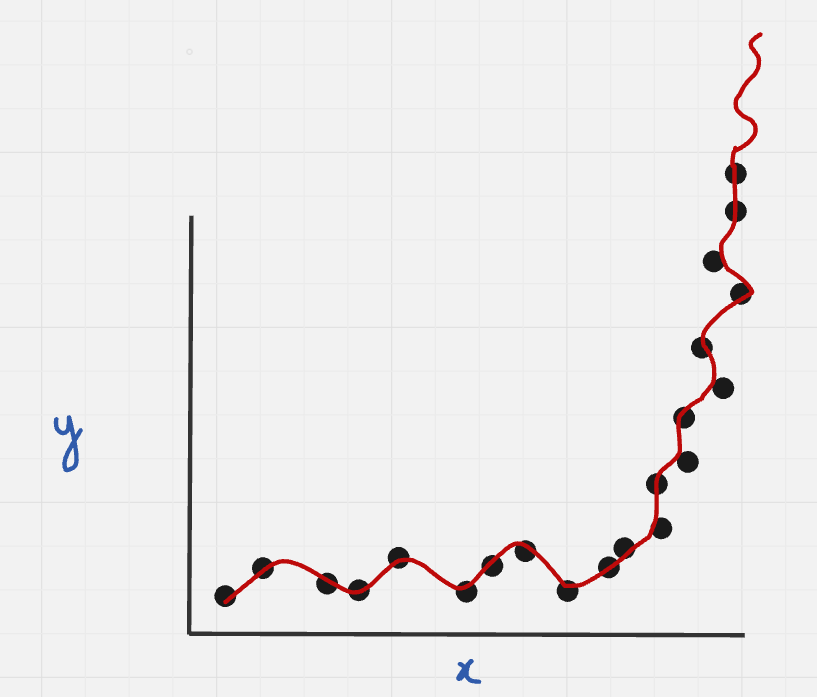

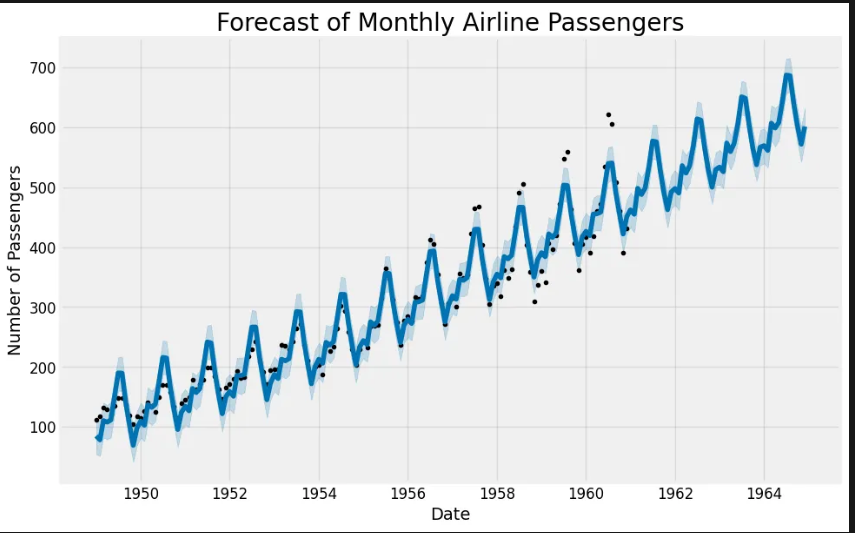

## Problem Statement: ##
Given data about COVID-19 patients, write code to visualize the impact and
analyze the trend of rate of infection and recovery as well as make predictions
about the number of cases expected a week in future based on the current
trends.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt

In [11]:
df = pd.read_csv("Covid_19_Clean_Complete (2).csv")
df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [13]:
df.shape

(49068, 10)

In [14]:
df.dtypes

,0
Province/State,object
Country/Region,object
Lat,float64
Long,float64
Date,object
Confirmed,int64
Deaths,int64
Recovered,int64
Active,int64
WHO Region,object


In [23]:
df.head(15)

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa
5,NaN,Antigua and Barbuda,17.06080,-61.796400,2020-01-22,0,0,0,0,Americas
6,NaN,Argentina,-38.41610,-63.616700,2020-01-22,0,0,0,0,Americas
7,NaN,Armenia,40.06910,45.038200,2020-01-22,0,0,0,0,Europe
8,Australian Capital Territory,Australia,-35.47350,149.012400,2020-01-22,0,0,0,0,Western Pacific
9,New South Wales,Australia,-33.86880,151.209300,2020-01-22,0,0,0,0,Western Pacific


In [25]:
df.tail(20)

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
49048,Northwest Territories,Canada,64.825500,-124.845700,2020-07-27,5,0,0,5,Americas
49049,Yukon,Canada,64.282300,-135.000000,2020-07-27,14,0,0,14,Americas
49050,NaN,Kosovo,42.602636,20.902977,2020-07-27,7413,185,4027,3201,Europe
49051,NaN,Burma,21.916200,95.956000,2020-07-27,350,6,292,52,South-East Asia
49052,Anguilla,United Kingdom,18.220600,-63.068600,2020-07-27,3,0,3,0,Europe
49053,British Virgin Islands,United Kingdom,18.420700,-64.640000,2020-07-27,8,1,7,0,Europe
49054,Turks and Caicos Islands,United Kingdom,21.694000,-71.797900,2020-07-27,99,2,36,61,Europe
49055,NaN,Botswana,-22.328500,24.684900,2020-07-27,739,2,63,674,Africa
49056,NaN,Burundi,-3.373100,29.918900,2020-07-27,378,1,301,76,Africa
49057,NaN,Sierra Leone,8.460555,-11.779889,2020-07-27,1783,66,1317,400,Africa


##1.  Convert Date to DateTime datatype

In [15]:
df["Date"] = pd.to_datetime(df["Date"])

In [16]:
df.dtypes

,0
Province/State,object
Country/Region,object
Lat,float64
Long,float64
Date,datetime64[ns]
Confirmed,int64
Deaths,int64
Recovered,int64
Active,int64
WHO Region,object


##2.  Find the first and last date of observation

In [17]:
print("First=", df["Date"].head(1))
print("Last=", df["Date"].tail(1))

First= 0   2020-01-22
Name: Date, dtype: datetime64[ns]
Last= 49067   2020-07-27
Name: Date, dtype: datetime64[ns]


##3. How many unique countries are there

In [18]:
df["Country/Region"].nunique()

187

In [19]:
df.rename(columns={"Province/State":"State","Country/Region":"Country"},inplace=True)
df.columns

Index(['State', 'Country', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths',
       'Recovered', 'Active', 'WHO Region'],
      dtype='object')

In [20]:
df["Country"].nunique()

187

In [22]:
df.head(187)

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa
...,...,...,...,...,...,...,...,...,...,...
182,NaN,Portugal,39.39990,-8.224500,2020-01-22,0,0,0,0,Europe
183,NaN,Qatar,25.35480,51.183900,2020-01-22,0,0,0,0,Eastern Mediterranean
184,NaN,Romania,45.94320,24.966800,2020-01-22,0,0,0,0,Europe
185,NaN,Russia,61.52401,105.318756,2020-01-22,0,0,0,0,Europe


# Global Dataset

In [26]:
global_df = df.groupby("Date")[["Confirmed","Deaths","Recovered","Active"]].sum()
global_df.head()

,Confirmed,Deaths,Recovered,Active
Date,,,,
2020-01-22,555,17,28,510
2020-01-23,654,18,30,606
2020-01-24,941,26,36,879
2020-01-25,1434,42,39,1353
2020-01-26,2118,56,52,2010


In [27]:
global_df.tail()

,Confirmed,Deaths,Recovered,Active
Date,,,,
2020-07-23,15510481,633506,8710969,6166006
2020-07-24,15791645,639650,8939705,6212290
2020-07-25,16047190,644517,9158743,6243930
2020-07-26,16251796,648621,9293464,6309711
2020-07-27,16480485,654036,9468087,6358362


#4. Find the most recent data/observations of Each Country

# or

#4. Find the total cases, deaths, recovered in all the countries.

In [29]:
recent_df = df[ df["Date"]==df["Date"].max()]
recent_df

# this dataframe tells us the total cases in all the countries

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
48807,NaN,Afghanistan,33.939110,67.709953,2020-07-27,36263,1269,25198,9796,Eastern Mediterranean
48808,NaN,Albania,41.153300,20.168300,2020-07-27,4880,144,2745,1991,Europe
48809,NaN,Algeria,28.033900,1.659600,2020-07-27,27973,1163,18837,7973,Africa
48810,NaN,Andorra,42.506300,1.521800,2020-07-27,907,52,803,52,Europe
48811,NaN,Angola,-11.202700,17.873900,2020-07-27,950,41,242,667,Africa
...,...,...,...,...,...,...,...,...,...,...
49063,NaN,Sao Tome and Principe,0.186400,6.613100,2020-07-27,865,14,734,117,Africa
49064,NaN,Yemen,15.552727,48.516388,2020-07-27,1691,483,833,375,Eastern Mediterranean
49065,NaN,Comoros,-11.645500,43.333300,2020-07-27,354,7,328,19,Africa
49066,NaN,Tajikistan,38.861000,71.276100,2020-07-27,7235,60,6028,1147,Europe


In [30]:
recent_df[recent_df["Country"]=="India"]

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
48936,NaN,India,20.593684,78.96288,2020-07-27,1480073,33408,951166,495499,South-East Asia


In [28]:
latest_df = df[df["Date"] == df["Date"].max()]
country_totals = latest_df.groupby("Country")[["Confirmed", "Deaths", "Recovered", "Active"]].sum().reset_index()
country_totals

,Country,Confirmed,Deaths,Recovered,Active
0,Afghanistan,36263,1269,25198,9796
1,Albania,4880,144,2745,1991
2,Algeria,27973,1163,18837,7973
3,Andorra,907,52,803,52
4,Angola,950,41,242,667
...,...,...,...,...,...
182,West Bank and Gaza,10621,78,3752,6791
183,Western Sahara,10,1,8,1
184,Yemen,1691,483,833,375
185,Zambia,4552,140,2815,1597


# 5. Find the top 5 countires with the most Confirmed Cases

In [31]:
top_5 = country_totals.sort_values(by="Confirmed", ascending=False).head(5)
top_5

,Country,Confirmed,Deaths,Recovered,Active
173,US,4290259,148011,1325804,2816444
23,Brazil,2442375,87618,1846641,508116
79,India,1480073,33408,951166,495499
138,Russia,816680,13334,602249,201097
154,South Africa,452529,7067,274925,170537


In [32]:
data = recent_df.groupby("Country")["Confirmed"].sum()
data.sort_values(ascending=False).head()

,Confirmed
Country,
US,4290259
Brazil,2442375
India,1480073
Russia,816680
South Africa,452529


# 6. Which 3 countries suffered the most Casualities

In [37]:
casualities=recent_df.groupby("Country")["Deaths"].sum()
casualities.sort_values(ascending=False).head(3)

,Deaths
Country,
US,148011
Brazil,87618
United Kingdom,45844


# 7. Show the Trend / Progression of Confirmed cases around the world using a line chart

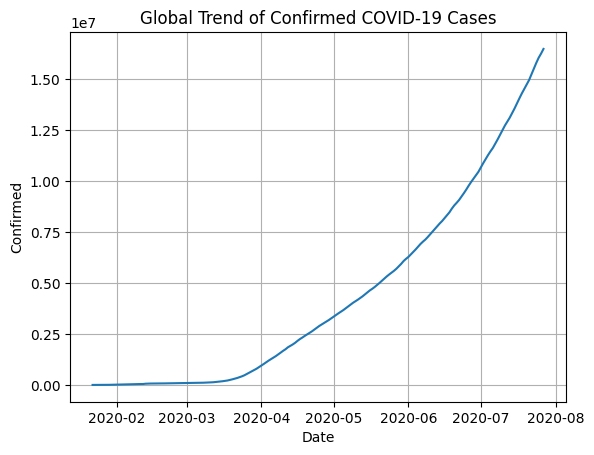

In [40]:
sb.lineplot(global_df["Confirmed"])
plt.title("Global Trend of Confirmed COVID-19 Cases")
plt.grid(True)
plt.show()

In [41]:
df

,State,Country,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.939110,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.153300,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.033900,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.506300,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.202700,17.873900,2020-01-22,0,0,0,0,Africa
...,...,...,...,...,...,...,...,...,...,...
49063,NaN,Sao Tome and Principe,0.186400,6.613100,2020-07-27,865,14,734,117,Africa
49064,NaN,Yemen,15.552727,48.516388,2020-07-27,1691,483,833,375,Eastern Mediterranean
49065,NaN,Comoros,-11.645500,43.333300,2020-07-27,354,7,328,19,Africa
49066,NaN,Tajikistan,38.861000,71.276100,2020-07-27,7235,60,6028,1147,Europe


# 8. Create a new column -> New Cases. Which will tell the number of new confirmed cases coming everyday.

In [43]:
global_df["New Cases"] = global_df["Confirmed"].diff()
global_df.iloc[0,4] = global_df.iloc[0,0]
global_df

,Confirmed,Deaths,Recovered,Active,New Cases
Date,,,,,
2020-01-22,555,17,28,510,555.0
2020-01-23,654,18,30,606,99.0
2020-01-24,941,26,36,879,287.0
2020-01-25,1434,42,39,1353,493.0
2020-01-26,2118,56,52,2010,684.0
...,...,...,...,...,...
2020-07-23,15510481,633506,8710969,6166006,282756.0
2020-07-24,15791645,639650,8939705,6212290,281164.0
2020-07-25,16047190,644517,9158743,6243930,255545.0


#9. Plot the New Cases.

[]

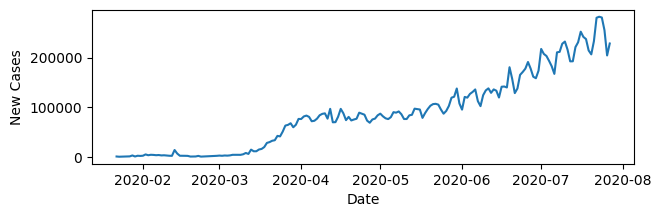

In [45]:
plt.figure(figsize=(7,2))
sb.lineplot(global_df["New Cases"])
plt.plot()

## Implement the Prophet model to covid_19.

In [46]:
!pip install prophet

from prophet import Prophet

# Prepare the dataset for Prophet
prophet_df = global_df.reset_index()[["Date", "Confirmed"]]
prophet_df.columns = ["ds", "y"]
prophet_df.head()

,ds,y
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118


In [47]:
global_df["Date"]= global_df.index
global_df.reset_index(inplace=True, drop=True)

In [48]:
# Initialize and Fit the Model
model=Prophet()
model.fit(prophet_df)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [49]:
# Creating the future dataframe/date
future_df = model.make_future_dataframe(31)
future_df

,ds
0,2020-01-22
1,2020-01-23
2,2020-01-24
3,2020-01-25
4,2020-01-26
...,...
214,2020-08-23
215,2020-08-24
216,2020-08-25
217,2020-08-26


In [55]:
# Visualization
prophet_df = global_df[["Date", "New Cases"]]
prophet_df.columns = ["ds", "y"]
prophet_df.head()

,ds,y
0,2020-01-22,555.0
1,2020-01-23,99.0
2,2020-01-24,287.0
3,2020-01-25,493.0
4,2020-01-26,684.0


In [56]:
model = Prophet()
model.fit(prophet_df)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


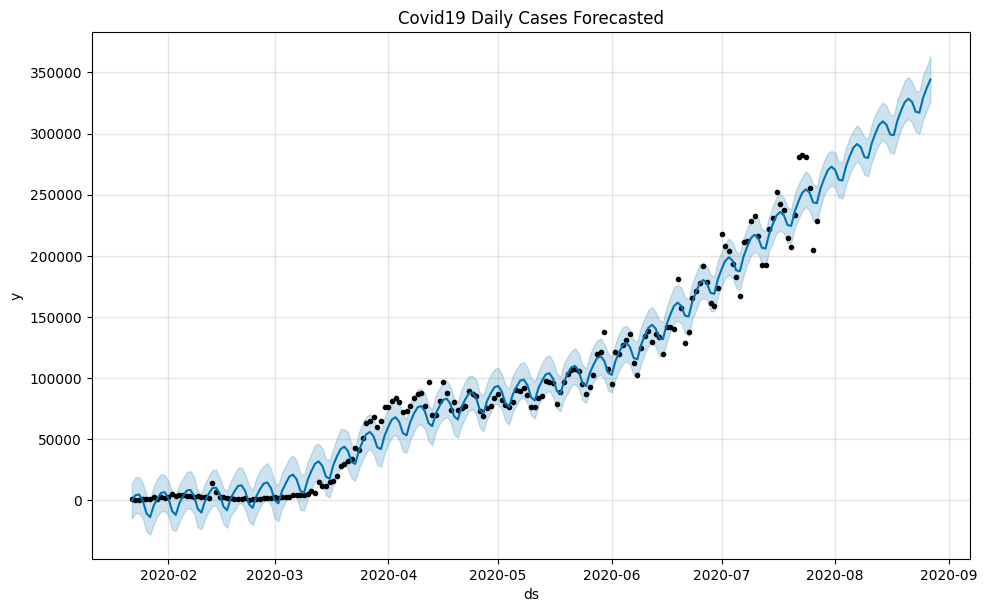

In [57]:
forecast = model.predict(future_df)
model.plot(forecast)
plt.title("Covid19 Daily Cases Forecasted")
plt.show()

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


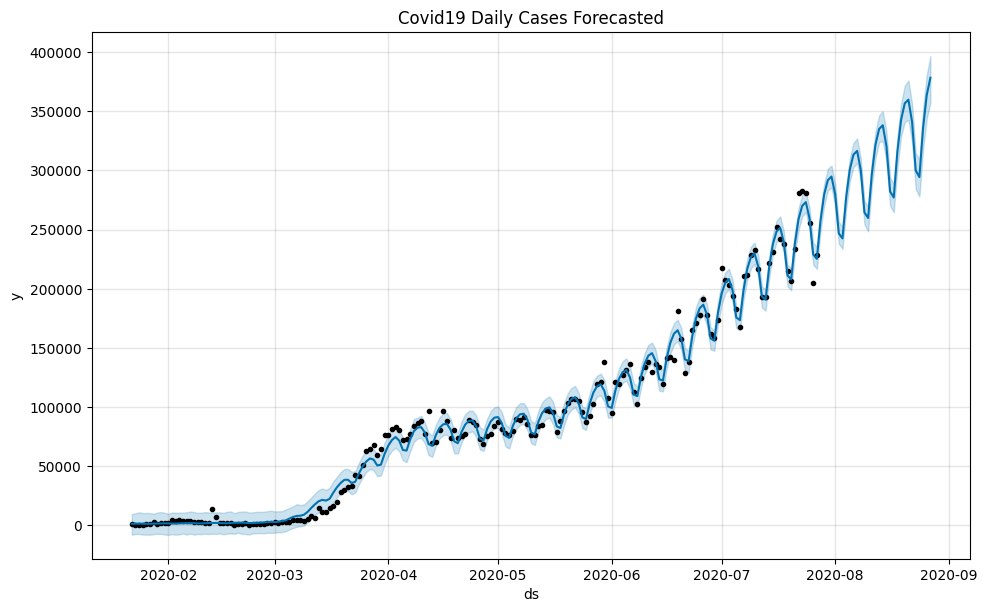

In [58]:
model = Prophet(
    seasonality_mode="multiplicative"
)
model.fit(prophet_df)

future_df = model.make_future_dataframe(31)

forecast = model.predict(future_df)

model.plot(forecast)
plt.title("Covid19 Daily Cases Forecasted")
plt.show()


1. Analyze Global Recovery & Mortality Rates

In [59]:
# Calculate Recovery Rate, Mortality Rate, and Daily Growth Rate (%)
global_df["Recovery Rate (%)"] = (global_df["Recovered"] / global_df["Confirmed"]) * 100
global_df["Mortality Rate (%)"] = (global_df["Deaths"] / global_df["Confirmed"]) * 100
global_df["Infection Growth Rate (%)"] = (global_df["New Cases"] / global_df["Confirmed"]) * 100

global_df[["Date", "Recovery Rate (%)", "Mortality Rate (%)", "Infection Growth Rate (%)"]].tail()

,Date,Recovery Rate (%),Mortality Rate (%),Infection Growth Rate (%)
183,2020-07-23,56.161824,4.084374,1.823000
184,2020-07-24,56.610347,4.050560,1.780460
185,2020-07-25,57.073812,4.016385,1.592459
186,2020-07-26,57.184228,3.991073,1.258975
187,2020-07-27,57.450293,3.968548,1.387635


2. Create Interactive Visualizations with Plotly

In [60]:
import plotly.express as px

# Interactive multi-line chart for Confirmed, Recovered, Active, and Deaths
fig_global = px.line(
    global_df,
    x="Date",
    y=["Confirmed", "Recovered", "Active", "Deaths"],
    title="Global COVID-19 Progression (Confirmed, Recovered, Active & Deaths)",
    labels={"value": "Number of Cases", "variable": "Metric"}
)
fig_global.show()

# Interactive Recovery vs Mortality Rate chart
fig_rates = px.line(
    global_df,
    x="Date",
    y=["Recovery Rate (%)", "Mortality Rate (%)"],
    title="Global COVID-19 Recovery Rate vs. Mortality Rate Over Time",
    labels={"value": "Percentage (%)", "variable": "Rate"}
)
fig_rates.show()

B. Interactive World Map (Choropleth)

In [61]:
fig_map = px.choropleth(
    country_totals,
    locations="Country",
    locationmode="country names",
    color="Confirmed",
    hover_name="Country",
    hover_data=["Deaths", "Recovered", "Active"],
    color_continuous_scale="Reds",
    title="Global COVID-19 Confirmed Cases by Country (as of July 27, 2020)"
)
fig_map.show()

C. Interactive Prophet Forecast (Combining Prophet + Plotly)

In [65]:
import pandas as pd
from prophet.plot import plot_plotly, plot_components_plotly

# Safely patch pandas Series and DataFrame boolean evaluations to return True if they contain elements
# This bypasses the obsolete truthiness check logic hardcoded inside older Prophet packages
original_series_bool = pd.Series.__bool__ if hasattr(pd.Series, '__bool__') else None
original_frame_bool = pd.DataFrame.__bool__ if hasattr(pd.DataFrame, '__bool__') else None

pd.Series.__bool__ = lambda self: not self.empty
pd.DataFrame.__bool__ = lambda self: not self.empty

try:
    # Interactive Prophet Forecast Chart
    fig_forecast = plot_plotly(model, forecast)
    fig_forecast.update_layout(title="Interactive Global Daily New Cases Forecast (Prophet + Plotly)")
    fig_forecast.show()

    # Interactive Trend & Seasonality Components
    fig_components = plot_components_plotly(model, forecast)
    fig_components.show()
finally:
    # Restore original pandas functions to avoid unexpected side effects in the rest of the notebook
    if original_series_bool is not None:
        pd.Series.__bool__ = original_series_bool
    if original_frame_bool is not None:
        pd.DataFrame.__bool__ = original_frame_bool

3. Extract the Exact 7-Day Future Prediction

In [66]:
# Filter predictions for the 7 days immediately following the last observation (2020-07-27)
next_7_days = forecast[forecast["ds"] > "2020-07-27"].head(7)[["ds", "yhat", "yhat_lower", "yhat_upper"]]
next_7_days.columns = ["Date", "Predicted Daily Cases", "Lower Bound", "Upper Bound"]
next_7_days

,Date,Predicted Daily Cases,Lower Bound,Upper Bound
188,2020-07-28,257546.892789,248543.192322,266411.941519
189,2020-07-29,279693.603708,270392.695414,288612.458534
190,2020-07-30,291720.659717,283071.547426,301458.661040
191,2020-07-31,294853.395352,285693.805826,304067.558789
192,2020-08-01,279915.105216,269923.192309,288607.850162
193,2020-08-02,246699.398821,238003.798494,256407.729495
194,2020-08-03,242498.144062,233666.295308,252386.047473


4. India-Specific Trend & 7-Day Forecast

In [69]:
import pandas as pd
import plotly.express as px
from prophet import Prophet
from prophet.plot import plot_plotly

# Filter dataset for India and calculate daily new cases & recovery rate
india_df = df[df["Country"] == "India"].groupby("Date")[["Confirmed", "Deaths", "Recovered", "Active"]].sum().reset_index()
india_df["New Cases"] = india_df["Confirmed"].diff().fillna(india_df["Confirmed"])
india_df["Recovery Rate (%)"] = (india_df["Recovered"] / india_df["Confirmed"]) * 100

# Interactive Plotly chart for India's trend
fig_india = px.line(
    india_df,
    x="Date",
    y=["Confirmed", "Recovered", "Active", "Deaths"],
    title="COVID-19 Trend in India",
    labels={"value": "Number of Cases", "variable": "Metric"}
)
fig_india.show()

# Prophet 7-Day Forecast for India's Confirmed Cases
india_prophet = india_df[["Date", "Confirmed"]].rename(columns={"Date": "ds", "Confirmed": "y"})
india_model = Prophet(seasonality_mode="multiplicative")
india_model.fit(india_prophet)

india_future = india_model.make_future_dataframe(periods=7)
india_forecast = india_model.predict(india_future)

# Safely patch pandas Series and DataFrame boolean evaluations during plot_plotly
original_series_bool = pd.Series.__bool__ if hasattr(pd.Series, '__bool__') else None
original_frame_bool = pd.DataFrame.__bool__ if hasattr(pd.DataFrame, '__bool__') else None

pd.Series.__bool__ = lambda self: not self.empty
pd.DataFrame.__bool__ = lambda self: not self.empty

try:
    # Interactive Plotly + Prophet forecast for India
    fig_india_forecast = plot_plotly(india_model, india_forecast)
    fig_india_forecast.update_layout(title="India COVID-19 Confirmed Cases - 7-Day Forecast")
    fig_india_forecast.show()
finally:
    if original_series_bool is not None:
        pd.Series.__bool__ = original_series_bool
    if original_frame_bool is not None:
        pd.DataFrame.__bool__ = original_frame_bool

# Print India's 7-day predicted table
india_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(7)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,1.321202e+06,1.285393e+06,1.355803e+06
189,2020-07-29,1.355449e+06,1.321172e+06,1.390378e+06
190,2020-07-30,1.392561e+06,1.358397e+06,1.428893e+06
191,2020-07-31,1.430064e+06,1.394302e+06,1.465422e+06
192,2020-08-01,1.467888e+06,1.433441e+06,1.502623e+06
193,2020-08-02,1.506085e+06,1.471225e+06,1.540713e+06
194,2020-08-03,1.539587e+06,1.504268e+06,1.575084e+06
